In [2]:
import mne

print(mne.__version__)

1.13.2


In [3]:
import mne

chemin = r"C:\UPJV\projet_solo\projet1\chb01_03.edf"

raw = mne.io.read_raw_edf(
    chemin,
    preload=True,
    verbose=False
)

print(raw)

<RawEDF | chb01_03.edf, 23 x 921600 (3600.0 s), ~161.7 MiB, data loaded>


C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\98053208.py:5: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(


In [4]:
print("Nombre de canaux :", len(raw.ch_names))
print("Fréquence d'échantillonnage :", raw.info["sfreq"], "Hz")
print("Nombre total de mesures :", raw.n_times)
print("Durée :", raw.times[-1], "secondes")

Nombre de canaux : 23
Fréquence d'échantillonnage : 256.0 Hz
Nombre total de mesures : 921600
Durée : 3599.99609375 secondes


In [5]:
print(raw.ch_names)

['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1']


In [6]:
data = raw.get_data()

print("Forme des données :", data.shape)

print("\nLes 10 premières valeurs du premier canal :")
print(data[0, :10])

Forme des données : (23, 921600)

Les 10 premières valeurs du premier canal :
[-1.77777778e-05  1.95360195e-07  1.95360195e-07  5.86080586e-07
  1.95360195e-07 -1.36752137e-06 -2.14896215e-06  5.86080586e-07
  2.93040293e-06 -5.86080586e-07]


In [7]:
data_uv = data * 1e6

print("Les 10 premières valeurs du premier canal en µV :")
print(data_uv[0, :10])

Les 10 premières valeurs du premier canal en µV :
[-17.77777778   0.1953602    0.1953602    0.58608059   0.1953602
  -1.36752137  -2.14896215   0.58608059   2.93040293  -0.58608059]


In [8]:
print(raw.ch_names[0])

FP1-F7


Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


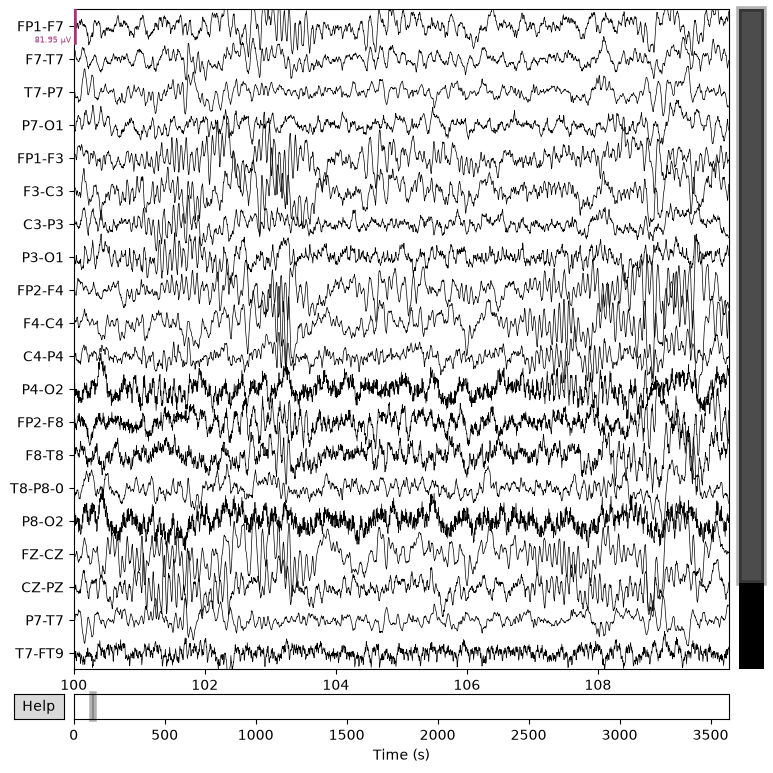

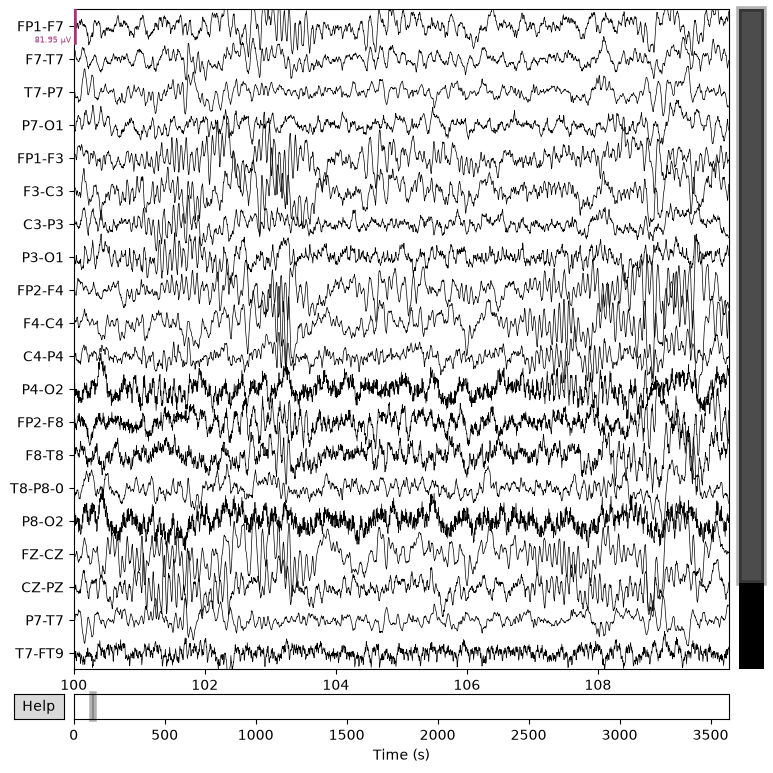

In [9]:
raw.plot(
    start=100,
    duration=10,
    scalings="auto"
)

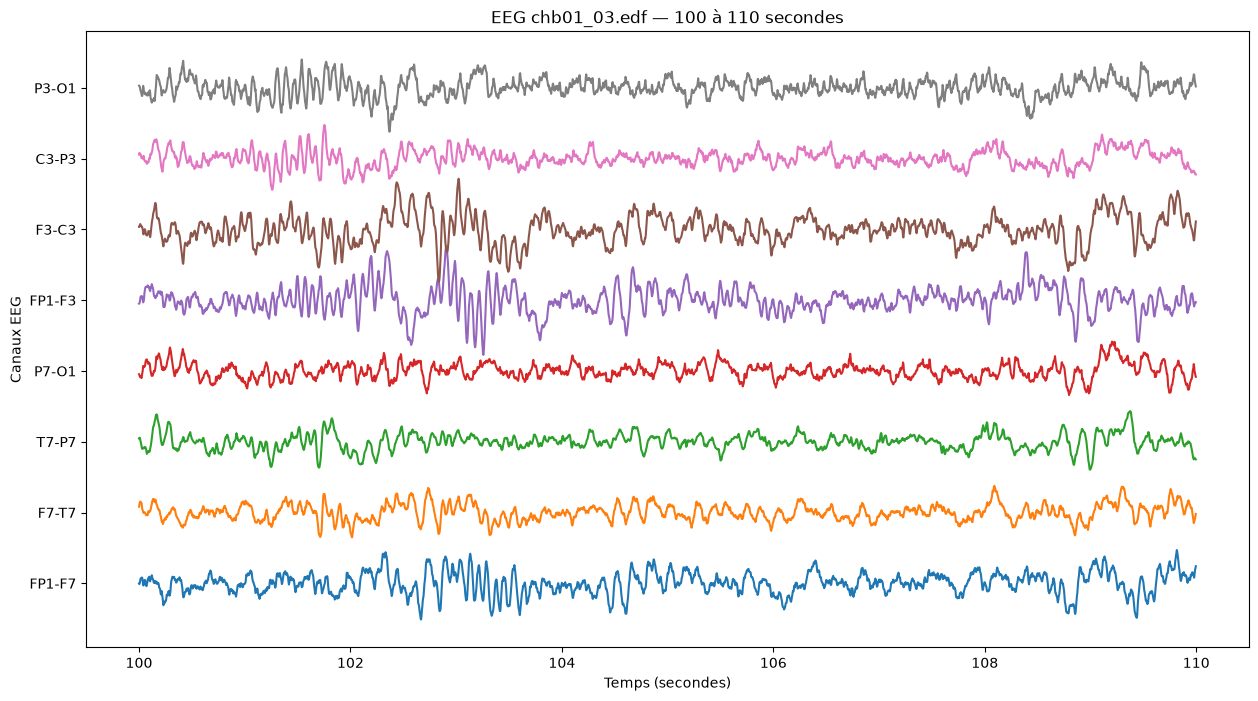

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Fréquence d'échantillonnage
sfreq = raw.info["sfreq"]

# On veut afficher de 100 s à 110 s
debut = 100
fin = 110

start_sample = int(debut * sfreq)
stop_sample = int(fin * sfreq)

# On prend les 8 premiers canaux pour que le graphique reste lisible
eeg = raw.get_data(
    picks=raw.ch_names[:8],
    start=start_sample,
    stop=stop_sample
) * 1e6   # conversion V -> µV

# Axe temporel
temps = np.arange(eeg.shape[1]) / sfreq + debut

plt.figure(figsize=(15, 8))

# Décalage vertical pour séparer les canaux
offset = 150

for i in range(eeg.shape[0]):
    plt.plot(
        temps,
        eeg[i] + i * offset
    )

plt.yticks(
    np.arange(eeg.shape[0]) * offset,
    raw.ch_names[:8]
)

plt.xlabel("Temps (secondes)")
plt.ylabel("Canaux EEG")
plt.title("EEG chb01_03.edf — 100 à 110 secondes")

plt.show()

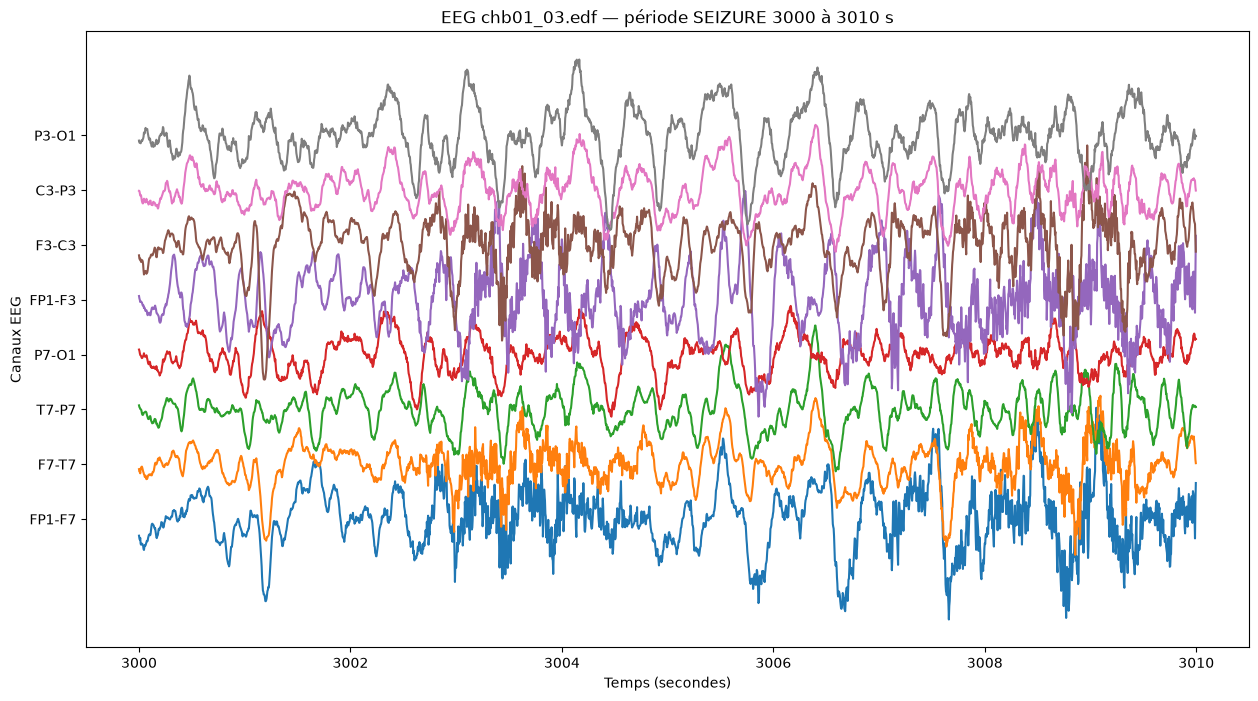

In [11]:
import matplotlib.pyplot as plt
import numpy as np

sfreq = raw.info["sfreq"]

debut = 3000
fin = 3010

start_sample = int(debut * sfreq)
stop_sample = int(fin * sfreq)

eeg = raw.get_data(
    picks=raw.ch_names[:8],
    start=start_sample,
    stop=stop_sample
) * 1e6

temps = np.arange(eeg.shape[1]) / sfreq + debut

plt.figure(figsize=(15, 8))

offset = 150

for i in range(eeg.shape[0]):
    plt.plot(temps, eeg[i] + i * offset)

plt.yticks(
    np.arange(eeg.shape[0]) * offset,
    raw.ch_names[:8]
)

plt.xlabel("Temps (secondes)")
plt.ylabel("Canaux EEG")
plt.title("EEG chb01_03.edf — période SEIZURE 3000 à 3010 s")

plt.show()

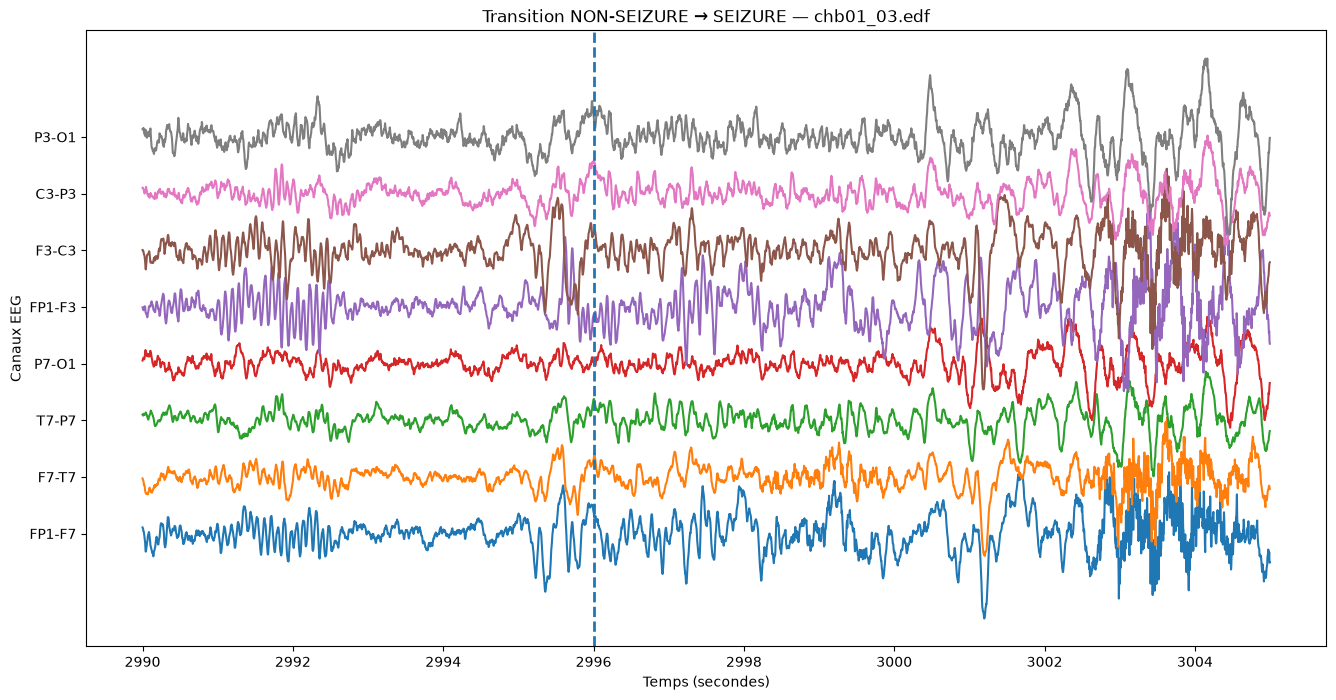

In [12]:
import matplotlib.pyplot as plt
import numpy as np

sfreq = raw.info["sfreq"]

debut = 2990
fin = 3005

start_sample = int(debut * sfreq)
stop_sample = int(fin * sfreq)

# Toujours les 8 premiers canaux pour l'instant
canaux = raw.ch_names[:8]

eeg = raw.get_data(
    picks=canaux,
    start=start_sample,
    stop=stop_sample
) * 1e6  # V -> µV

temps = np.arange(eeg.shape[1]) / sfreq + debut

plt.figure(figsize=(16, 8))

offset = 150

for i in range(eeg.shape[0]):
    plt.plot(
        temps,
        eeg[i] + i * offset
    )

plt.yticks(
    np.arange(len(canaux)) * offset,
    canaux
)

# Ligne correspondant au début annoté de la crise
plt.axvline(
    x=2996,
    linestyle="--",
    linewidth=2
)

plt.xlabel("Temps (secondes)")
plt.ylabel("Canaux EEG")
plt.title("Transition NON-SEIZURE → SEIZURE — chb01_03.edf")

plt.show()

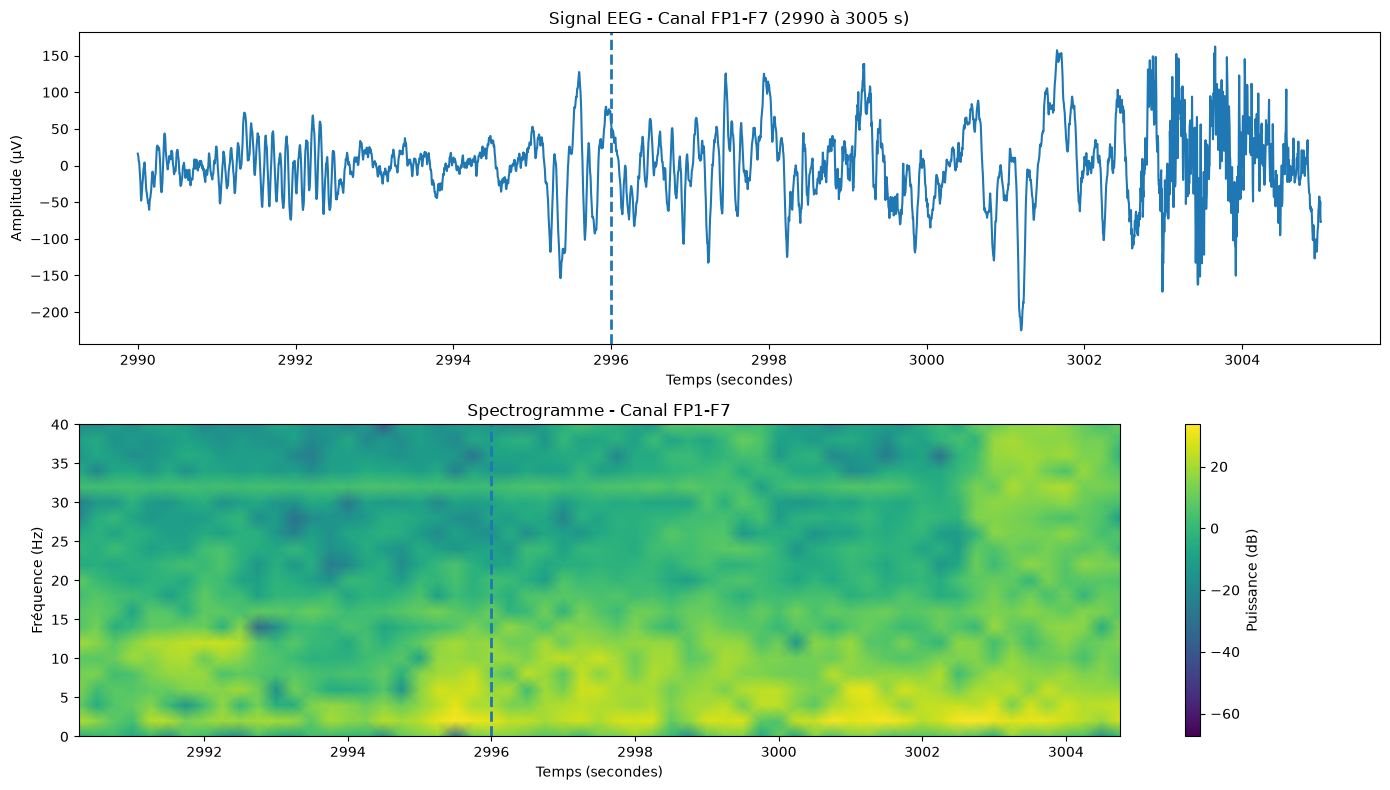

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

# -----------------------------
# Paramètres
# -----------------------------
canal = "FP1-F7"
debut = 2990
fin = 3005

sfreq = raw.info["sfreq"]

# -----------------------------
# Extraire le signal
# -----------------------------
start_sample = int(debut * sfreq)
stop_sample = int(fin * sfreq)

signal = raw.get_data(
    picks=[canal],
    start=start_sample,
    stop=stop_sample
)[0] * 1e6   # conversion en µV

temps = np.arange(len(signal)) / sfreq + debut

# -----------------------------
# Calcul du spectrogramme
# -----------------------------
f, t, Sxx = spectrogram(
    signal,
    fs=sfreq,
    nperseg=128,
    noverlap=64,
    scaling="density",
    mode="psd"
)

# t commence à 0, on le remet dans le temps réel
t = t + debut

# passage en dB pour mieux visualiser
Sxx_db = 10 * np.log10(Sxx + 1e-12)

# -----------------------------
# Affichage
# -----------------------------
plt.figure(figsize=(14, 8))

# 1) signal EEG
plt.subplot(2, 1, 1)
plt.plot(temps, signal)
plt.axvline(2996, linestyle="--", linewidth=2)
plt.title(f"Signal EEG - Canal {canal} ({debut} à {fin} s)")
plt.xlabel("Temps (secondes)")
plt.ylabel("Amplitude (µV)")

# 2) spectrogramme
plt.subplot(2, 1, 2)
plt.pcolormesh(t, f, Sxx_db, shading="gouraud")
plt.axvline(2996, linestyle="--", linewidth=2)
plt.ylim(0, 40)   # on affiche 0 à 40 Hz pour commencer
plt.xlabel("Temps (secondes)")
plt.ylabel("Fréquence (Hz)")
plt.title(f"Spectrogramme - Canal {canal}")
plt.colorbar(label="Puissance (dB)")

plt.tight_layout()
plt.show()

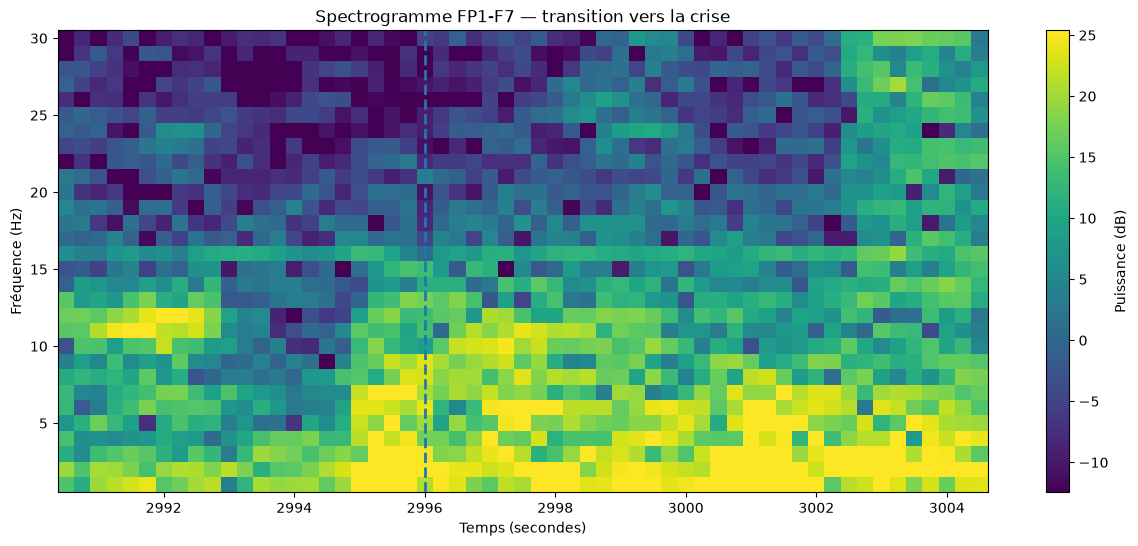

In [14]:
from scipy.signal import spectrogram
import numpy as np
import matplotlib.pyplot as plt

f, t, Sxx = spectrogram(
    signal,
    fs=sfreq,
    nperseg=256,
    noverlap=192,
    scaling="density",
    mode="psd"
)

t = t + debut

Sxx_db = 10 * np.log10(Sxx + 1e-12)

# On garde seulement 0.5 à 30 Hz pour l'affichage
mask = (f >= 0.5) & (f <= 30)

f_aff = f[mask]
Sxx_aff = Sxx_db[mask, :]

# Échelle robuste pour éviter que quelques valeurs extrêmes
# rendent toute l'image illisible
vmin = np.percentile(Sxx_aff, 5)
vmax = np.percentile(Sxx_aff, 95)

plt.figure(figsize=(15, 6))

plt.pcolormesh(
    t,
    f_aff,
    Sxx_aff,
    shading="auto",
    vmin=vmin,
    vmax=vmax
)

plt.axvline(
    2996,
    linestyle="--",
    linewidth=2
)

plt.xlabel("Temps (secondes)")
plt.ylabel("Fréquence (Hz)")
plt.title("Spectrogramme FP1-F7 — transition vers la crise")

plt.colorbar(label="Puissance (dB)")

plt.show()

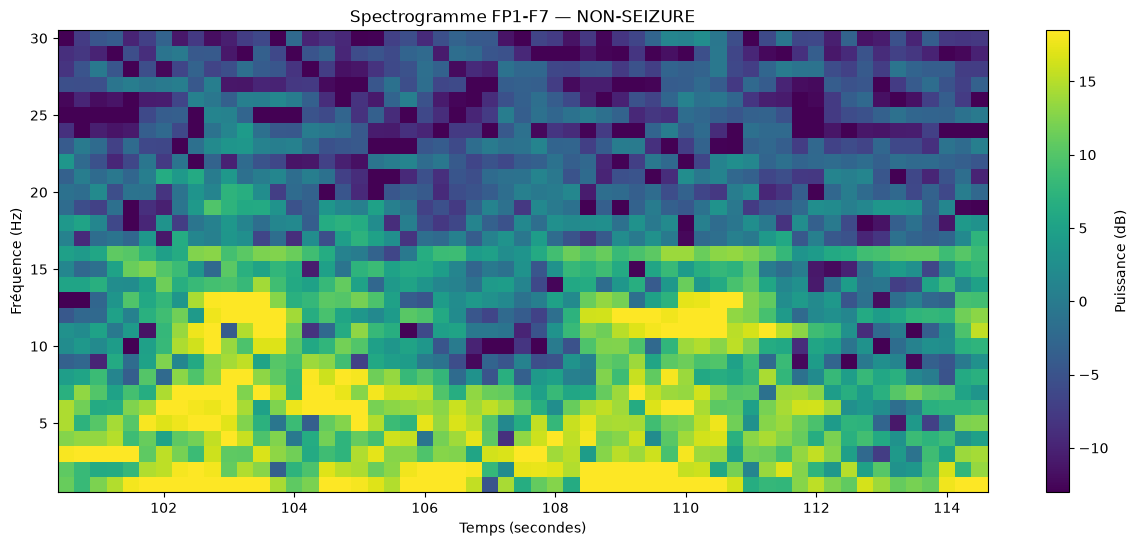

In [15]:
from scipy.signal import spectrogram
import numpy as np
import matplotlib.pyplot as plt

canal = "FP1-F7"

debut = 100
fin = 115

sfreq = raw.info["sfreq"]

start_sample = int(debut * sfreq)
stop_sample = int(fin * sfreq)

signal_normal = raw.get_data(
    picks=[canal],
    start=start_sample,
    stop=stop_sample
)[0] * 1e6

f, t, Sxx = spectrogram(
    signal_normal,
    fs=sfreq,
    nperseg=256,
    noverlap=192,
    scaling="density",
    mode="psd"
)

t = t + debut

Sxx_db = 10 * np.log10(Sxx + 1e-12)

mask = (f >= 0.5) & (f <= 30)

f_aff = f[mask]
Sxx_aff = Sxx_db[mask, :]

vmin = np.percentile(Sxx_aff, 5)
vmax = np.percentile(Sxx_aff, 95)

plt.figure(figsize=(15, 6))

plt.pcolormesh(
    t,
    f_aff,
    Sxx_aff,
    shading="auto",
    vmin=vmin,
    vmax=vmax
)

plt.xlabel("Temps (secondes)")
plt.ylabel("Fréquence (Hz)")
plt.title("Spectrogramme FP1-F7 — NON-SEIZURE")

plt.colorbar(label="Puissance (dB)")

plt.show()

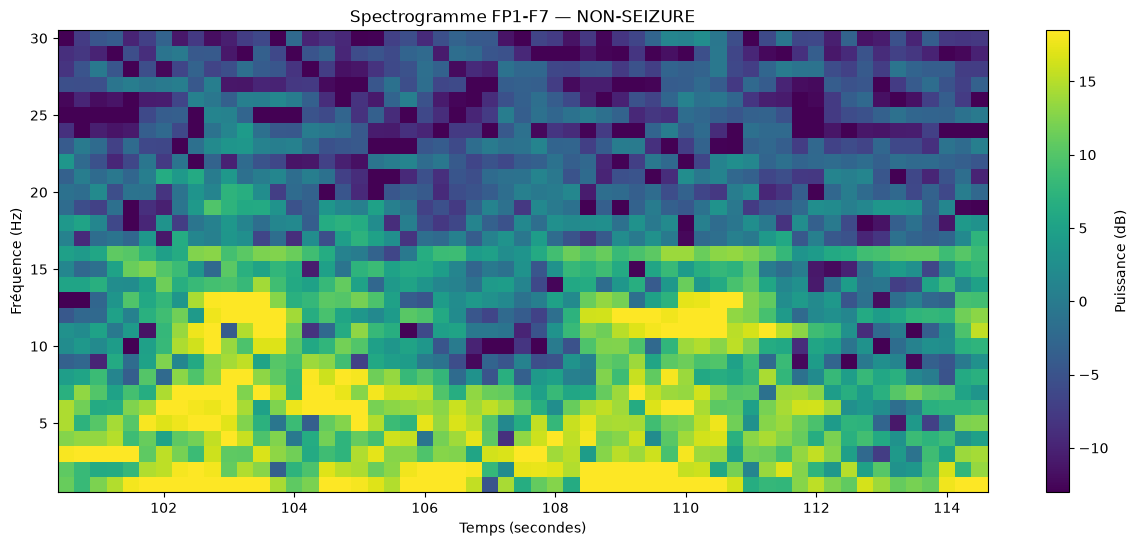

In [16]:
from scipy.signal import spectrogram
import numpy as np
import matplotlib.pyplot as plt

canal = "FP1-F7"
debut = 100
fin = 115

sfreq = raw.info["sfreq"]

start_sample = int(debut * sfreq)
stop_sample = int(fin * sfreq)

signal_normal = raw.get_data(
    picks=[canal],
    start=start_sample,
    stop=stop_sample
)[0] * 1e6

f, t, Sxx = spectrogram(
    signal_normal,
    fs=sfreq,
    nperseg=256,
    noverlap=192,
    scaling="density",
    mode="psd"
)

t = t + debut

Sxx_db = 10 * np.log10(Sxx + 1e-12)

mask = (f >= 0.5) & (f <= 30)

f_aff = f[mask]
Sxx_aff = Sxx_db[mask, :]

vmin = np.percentile(Sxx_aff, 5)
vmax = np.percentile(Sxx_aff, 95)

plt.figure(figsize=(15, 6))

plt.pcolormesh(
    t,
    f_aff,
    Sxx_aff,
    shading="auto",
    vmin=vmin,
    vmax=vmax
)

plt.xlabel("Temps (secondes)")
plt.ylabel("Fréquence (Hz)")
plt.title("Spectrogramme FP1-F7 — NON-SEIZURE")

plt.colorbar(label="Puissance (dB)")

plt.show()

In [17]:
import pandas as pd

# Paramètres
duree_eeg = raw.n_times / raw.info["sfreq"]

window_size = 5   # secondes
stride = 1        # secondes

seizure_start = 2996
seizure_end = 3036

fenetres = []

start = 0

while start + window_size <= duree_eeg:

    end = start + window_size

    # Fenêtre entièrement pendant la crise
    if start >= seizure_start and end <= seizure_end:
        label = 1

    # Fenêtre qui chevauche partiellement la crise
    elif start < seizure_end and end > seizure_start:
        label = 2

    # Aucun chevauchement avec la crise
    else:
        label = 0

    fenetres.append({
        "debut": start,
        "fin": end,
        "label": label
    })

    start += stride

df_fenetres = pd.DataFrame(fenetres)

print(df_fenetres.head(10))
print("\nNombre total de fenêtres :", len(df_fenetres))
print("\nRépartition des labels :")
print(df_fenetres["label"].value_counts().sort_index())

   debut  fin  label
0      0    5      0
1      1    6      0
2      2    7      0
3      3    8      0
4      4    9      0
5      5   10      0
6      6   11      0
7      7   12      0
8      8   13      0
9      9   14      0

Nombre total de fenêtres : 3596

Répartition des labels :
label
0    3552
1      36
2       8
Name: count, dtype: int64


In [18]:
import pandas as pd

# =========================
# PARAMÈTRES DU FICHIER EEG
# =========================

# Durée totale de l'EEG en secondes
duree_eeg = raw.n_times / raw.info["sfreq"]

# Taille d'une fenêtre
window_size = 5  # secondes

# Décalage entre deux fenêtres successives
stride = 1  # seconde

# Annotation de la crise dans chb01_03.edf
seizure_start = 2996  # secondes
seizure_end = 3036    # secondes


# =========================
# CRÉATION DES FENÊTRES
# =========================

fenetres = []

start = 0

while start + window_size <= duree_eeg:

    end = start + window_size

    # Cas 1 :
    # la fenêtre est entièrement comprise dans la crise
    if start >= seizure_start and end <= seizure_end:
        label = 1

    # Cas 2 :
    # la fenêtre chevauche partiellement la crise
    elif start < seizure_end and end > seizure_start:
        label = 2

    # Cas 3 :
    # la fenêtre ne touche pas du tout la crise
    else:
        label = 0

    fenetres.append({
        "debut": start,
        "fin": end,
        "label": label
    })

    # déplacement de la fenêtre de 1 seconde
    start += stride


# =========================
# CRÉATION DU DATAFRAME
# =========================

df_fenetres = pd.DataFrame(fenetres)


# =========================
# AFFICHAGE DES RÉSULTATS
# =========================

print("Premières fenêtres :")
print(df_fenetres.head(10))

print("\nNombre total de fenêtres :", len(df_fenetres))

print("\nRépartition des labels :")
print(df_fenetres["label"].value_counts().sort_index())


# =========================
# VÉRIFICATION AUTOUR DU DÉBUT DE LA CRISE
# =========================

print("\nFenêtres autour du début de la crise :")

print(
    df_fenetres[
        (df_fenetres["debut"] >= 2990) &
        (df_fenetres["debut"] <= 3002)
    ]
)


# =========================
# EXEMPLE PRÉCIS : 3000 → 3005 s
# =========================

print("\nFenêtre 3000 → 3005 secondes :")

print(
    df_fenetres[
        df_fenetres["debut"] == 3000
    ]
)


# =========================
# TOUTES LES FENÊTRES SEIZURE
# =========================

print("\nPremières fenêtres avec label = 1 :")

print(
    df_fenetres[
        df_fenetres["label"] == 1
    ].head(10)
)

Premières fenêtres :
   debut  fin  label
0      0    5      0
1      1    6      0
2      2    7      0
3      3    8      0
4      4    9      0
5      5   10      0
6      6   11      0
7      7   12      0
8      8   13      0
9      9   14      0

Nombre total de fenêtres : 3596

Répartition des labels :
label
0    3552
1      36
2       8
Name: count, dtype: int64

Fenêtres autour du début de la crise :
      debut   fin  label
2990   2990  2995      0
2991   2991  2996      0
2992   2992  2997      2
2993   2993  2998      2
2994   2994  2999      2
2995   2995  3000      2
2996   2996  3001      1
2997   2997  3002      1
2998   2998  3003      1
2999   2999  3004      1
3000   3000  3005      1
3001   3001  3006      1
3002   3002  3007      1

Fenêtre 3000 → 3005 secondes :
      debut   fin  label
3000   3000  3005      1

Premières fenêtres avec label = 1 :
      debut   fin  label
2996   2996  3001      1
2997   2997  3002      1
2998   2998  3003      1
2999   2999  3004 

In [20]:
import numpy as np

sfreq = raw.info["sfreq"]

# Fenêtre SEIZURE
debut = 3000
fin = 3005

# Conversion du temps en indices d'échantillons
start_sample = int(debut * sfreq)
stop_sample = int(fin * sfreq)

# Extraction des vraies données EEG
X_seizure = raw.get_data(
    start=start_sample,
    stop=stop_sample
)

print("Début sample 3000*256:", start_sample)
print("Fin sample 3005*256 :", stop_sample)
print("Fin sample  :", stop_sample)
print("Forme de la fenêtre :", X_seizure.shape)
print("Label :", 1)

Début sample 3000*256: 768000
Fin sample 3005*256 : 769280
Fin sample  : 769280
Forme de la fenêtre : (23, 1280)
Label : 1


In [21]:
debut = 100
fin = 105

start_sample = int(debut * sfreq)
stop_sample = int(fin * sfreq)

X_non_seizure = raw.get_data(
    start=start_sample,
    stop=stop_sample
)

print("Forme de la fenêtre :", X_non_seizure.shape)
print("Label :", 0)

Forme de la fenêtre : (23, 1280)
Label : 0


In [22]:
import numpy as np

# ==============================
# PARAMÈTRES
# ==============================

sfreq = int(raw.info["sfreq"])   # 256 Hz
window_size = 5                  # secondes

n_channels = len(raw.ch_names)   # 23 canaux
n_samples = window_size * sfreq  # 5 × 256 = 1280


# ==============================
# GARDER UNIQUEMENT LABEL 0 ET 1
# ==============================

df_utilisable = df_fenetres[
    df_fenetres["label"].isin([0, 1])
].reset_index(drop=True)

print("Nombre de fenêtres utilisables :", len(df_utilisable))


# ==============================
# PRÉPARER X ET y
# ==============================

X = np.empty(
    (len(df_utilisable), n_channels, n_samples),
    dtype=np.float32
)

y = df_utilisable["label"].to_numpy(dtype=np.int8)


# ==============================
# EXTRACTION DES FENÊTRES EEG
# ==============================

for i, ligne in df_utilisable.iterrows():

    debut = ligne["debut"]
    fin = ligne["fin"]

    # secondes → samples
    start_sample = int(debut * sfreq)
    stop_sample = int(fin * sfreq)

    # Extraction EEG
    fenetre = raw.get_data(
        start=start_sample,
        stop=stop_sample
    )

    # Conversion V → µV
    fenetre = fenetre * 1e6

    # Stockage
    X[i] = fenetre.astype(np.float32)


# ==============================
# VÉRIFICATIONS
# ==============================

print("\nForme de X :", X.shape)
print("Forme de y :", y.shape)

print("\nNombre NON-SEIZURE :", np.sum(y == 0))
print("Nombre SEIZURE :", np.sum(y == 1))

Nombre de fenêtres utilisables : 3588

Forme de X : (3588, 23, 1280)
Forme de y : (3588,)

Nombre NON-SEIZURE : 3552
Nombre SEIZURE : 36


In [23]:
seizure_start = 2996
seizure_end = 3036

In [24]:
import re
from pathlib import Path

dossier_chb02 = Path(r"C:\UPJV\projet_solo\projet1\chb02")

summary_path = dossier_chb02 / "chb02-summary.txt"

texte = summary_path.read_text(encoding="utf-8", errors="ignore")


# Chaque bloc commence par "File Name:"
blocs = re.split(r"(?=File Name:)", texte)

annotations = {}

for bloc in blocs:

    match_file = re.search(r"File Name:\s*(\S+\.edf)", bloc)

    if not match_file:
        continue

    nom_fichier = match_file.group(1)

    starts = re.findall(
        r"Seizure(?: \d+)? Start Time:\s*(\d+)\s*seconds",
        bloc
    )

    ends = re.findall(
        r"Seizure(?: \d+)? End Time:\s*(\d+)\s*seconds",
        bloc
    )

    crises = [
        (int(start), int(end))
        for start, end in zip(starts, ends)
    ]

    annotations[nom_fichier] = crises


# Affichage
for fichier, crises in annotations.items():

    if crises:
        print(f"{fichier} -> {crises}")

chb02_16.edf -> [(130, 212)]
chb02_16+.edf -> [(2972, 3053)]
chb02_19.edf -> [(3369, 3378)]


In [25]:
import mne
import numpy as np
import pandas as pd

window_size = 5
stride = 1

toutes_fenetres = []

# Tous les EDF réellement présents dans ton dossier
fichiers_edf = sorted(dossier_chb02.glob("*.edf"))

for chemin_edf in fichiers_edf:

    nom_fichier = chemin_edf.name

    print(f"\nTraitement : {nom_fichier}")

    # -------------------------
    # Lecture EEG
    # -------------------------

    raw_patient = mne.io.read_raw_edf(
        chemin_edf,
        preload=False,
        verbose=False
    )

    sfreq = raw_patient.info["sfreq"]

    duree = raw_patient.n_times / sfreq

    # Crises annotées de ce fichier
    crises = annotations.get(nom_fichier, [])

    print("Durée :", duree, "s")
    print("Fréquence :", sfreq, "Hz")
    print("Nombre canaux :", len(raw_patient.ch_names))
    print("Crises :", crises)

    # -------------------------
    # Création des fenêtres
    # -------------------------

    start = 0

    while start + window_size <= duree:

        end = start + window_size

        label = 0

        for seizure_start, seizure_end in crises:

            # Entièrement dans la crise
            if start >= seizure_start and end <= seizure_end:
                label = 1
                break

            # Chevauche partiellement une crise
            elif start < seizure_end and end > seizure_start:
                label = 2
                break

        toutes_fenetres.append({
            "patient": "chb02",
            "fichier": nom_fichier,
            "debut": start,
            "fin": end,
            "label": label
        })

        start += stride


df_chb02 = pd.DataFrame(toutes_fenetres)


Traitement : chb02_01.edf
Durée : 3600.0 s
Fréquence : 256.0 Hz
Nombre canaux : 23
Crises : []

Traitement : chb02_02.edf
Durée : 3600.0 s
Fréquence : 256.0 Hz
Nombre canaux : 23
Crises : []

Traitement : chb02_16.edf
Durée : 959.0 s
Fréquence : 256.0 Hz
Nombre canaux : 23
Crises : [(130, 212)]

Traitement : chb02_19.edf
Durée : 3600.0 s
Fréquence : 256.0 Hz
Nombre canaux : 23
Crises : [(3369, 3378)]


C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\4256518849.py:23: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_patient = mne.io.read_raw_edf(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\4256518849.py:23: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_patient = mne.io.read_raw_edf(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\4256518849.py:23: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_patient = mne.io.read_raw_edf(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\4256518849.py:23: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_patient = mne.io.read_raw_edf(


In [26]:
print(df_chb02.head())

print("\nNombre total de fenêtres :")
print(len(df_chb02))

print("\nRépartition des labels :")
print(
    df_chb02["label"]
    .value_counts()
    .sort_index()
)

  patient       fichier  debut  fin  label
0   chb02  chb02_01.edf      0    5      0
1   chb02  chb02_01.edf      1    6      0
2   chb02  chb02_01.edf      2    7      0
3   chb02  chb02_01.edf      3    8      0
4   chb02  chb02_01.edf      4    9      0

Nombre total de fenêtres :
11743

Répartition des labels :
label
0    11644
1       83
2       16
Name: count, dtype: int64


In [27]:
df_chb02[df_chb02["label"] == 1].head(20)

,patient,fichier,debut,fin,label
7322,chb02,chb02_16.edf,130,135,1
7323,chb02,chb02_16.edf,131,136,1
7324,chb02,chb02_16.edf,132,137,1
7325,chb02,chb02_16.edf,133,138,1
7326,chb02,chb02_16.edf,134,139,1
7327,chb02,chb02_16.edf,135,140,1
7328,chb02,chb02_16.edf,136,141,1
7329,chb02,chb02_16.edf,137,142,1
7330,chb02,chb02_16.edf,138,143,1
7331,chb02,chb02_16.edf,139,144,1


In [28]:
import mne
import numpy as np


def extraire_fenetre(ligne, dossier):

    # -----------------------------
    # 1. Trouver le fichier EDF
    # -----------------------------

    chemin_edf = dossier / ligne["fichier"]

    # -----------------------------
    # 2. Ouvrir l'EEG
    # -----------------------------

    raw_temp = mne.io.read_raw_edf(
        chemin_edf,
        preload=False,
        verbose=False
    )

    # Fréquence d'échantillonnage
    sfreq = raw_temp.info["sfreq"]

    # -----------------------------
    # 3. Convertir secondes → samples
    # -----------------------------

    start_sample = int(ligne["debut"] * sfreq)
    stop_sample = int(ligne["fin"] * sfreq)

    # -----------------------------
    # 4. Extraire les données EEG
    # -----------------------------

    X = raw_temp.get_data(
        start=start_sample,
        stop=stop_sample
    )

    # Volts → microvolts
    X = X * 1e6

    # Label correspondant
    y = int(ligne["label"])

    return X.astype(np.float32), y

In [29]:
ligne_seizure = df_chb02[
    df_chb02["label"] == 1
].iloc[0]

print(ligne_seizure)

patient           chb02
fichier    chb02_16.edf
debut               130
fin                 135
label                 1
Name: 7322, dtype: object


In [30]:
X_test, y_test = extraire_fenetre(
    ligne_seizure,
    dossier_chb02
)

print("\nForme de X :", X_test.shape)
print("Label :", y_test)


Forme de X : (23, 1280)
Label : 1


C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\3897334445.py:17: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_temp = mne.io.read_raw_edf(


In [31]:
ligne_normal = df_chb02[
    df_chb02["label"] == 0
].iloc[0]

X_normal, y_normal = extraire_fenetre(
    ligne_normal,
    dossier_chb02
)

print("Fichier :", ligne_normal["fichier"])
print("Temps :", ligne_normal["debut"], "→", ligne_normal["fin"])

print("Forme de X :", X_normal.shape)
print("Label :", y_normal)

Fichier : chb02_01.edf
Temps : 0 → 5
Forme de X : (23, 1280)
Label : 0


C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\3897334445.py:17: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_temp = mne.io.read_raw_edf(


In [32]:
for chemin_edf in fichiers_edf:

    raw_check = mne.io.read_raw_edf(
        chemin_edf,
        preload=False,
        verbose=False
    )

    print("\n", chemin_edf.name)
    print("Nombre de canaux :", len(raw_check.ch_names))

    for i, canal in enumerate(raw_check.ch_names):
        print(i, canal)


 chb02_01.edf
Nombre de canaux : 23
0 FP1-F7
1 F7-T7
2 T7-P7
3 P7-O1
4 FP1-F3
5 F3-C3
6 C3-P3
7 P3-O1
8 FP2-F4
9 F4-C4
10 C4-P4
11 P4-O2
12 FP2-F8
13 F8-T8
14 T8-P8-0
15 P8-O2
16 FZ-CZ
17 CZ-PZ
18 P7-T7
19 T7-FT9
20 FT9-FT10
21 FT10-T8
22 T8-P8-1

 chb02_02.edf
Nombre de canaux : 23
0 FP1-F7
1 F7-T7
2 T7-P7
3 P7-O1
4 FP1-F3
5 F3-C3
6 C3-P3
7 P3-O1
8 FP2-F4
9 F4-C4
10 C4-P4
11 P4-O2
12 FP2-F8
13 F8-T8
14 T8-P8-0
15 P8-O2
16 FZ-CZ
17 CZ-PZ
18 P7-T7
19 T7-FT9
20 FT9-FT10
21 FT10-T8
22 T8-P8-1

 chb02_16.edf
Nombre de canaux : 23
0 FP1-F7
1 F7-T7
2 T7-P7
3 P7-O1
4 FP1-F3
5 F3-C3
6 C3-P3
7 P3-O1
8 FP2-F4
9 F4-C4
10 C4-P4
11 P4-O2
12 FP2-F8
13 F8-T8
14 T8-P8-0
15 P8-O2
16 FZ-CZ
17 CZ-PZ
18 P7-T7
19 T7-FT9
20 FT9-FT10
21 FT10-T8
22 T8-P8-1

 chb02_19.edf
Nombre de canaux : 23
0 FP1-F7
1 F7-T7
2 T7-P7
3 P7-O1
4 FP1-F3
5 F3-C3
6 C3-P3
7 P3-O1
8 FP2-F4
9 F4-C4
10 C4-P4
11 P4-O2
12 FP2-F8
13 F8-T8
14 T8-P8-0
15 P8-O2
16 FZ-CZ
17 CZ-PZ
18 P7-T7
19 T7-FT9
20 FT9-FT10
21 FT10-T8
22 T8-P8-1


C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\1401138233.py:3: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_check = mne.io.read_raw_edf(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\1401138233.py:3: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_check = mne.io.read_raw_edf(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\1401138233.py:3: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_check = mne.io.read_raw_edf(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\1401138233.py:3: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_check = mne.io.read_raw_edf(


In [33]:
listes_canaux = {}

for chemin_edf in fichiers_edf:

    raw_check = mne.io.read_raw_edf(
        chemin_edf,
        preload=False,
        verbose=False
    )

    listes_canaux[chemin_edf.name] = raw_check.ch_names


# Fichier de référence
fichier_ref = fichiers_edf[0].name
canaux_ref = listes_canaux[fichier_ref]

print("Fichier de référence :", fichier_ref)
print("Nombre de canaux :", len(canaux_ref))

for fichier, canaux in listes_canaux.items():

    identiques = canaux == canaux_ref

    print(
        fichier,
        "->",
        "MÊMES CANAUX" if identiques else "CANAUX DIFFÉRENTS"
    )

Fichier de référence : chb02_01.edf
Nombre de canaux : 23
chb02_01.edf -> MÊMES CANAUX
chb02_02.edf -> MÊMES CANAUX
chb02_16.edf -> MÊMES CANAUX
chb02_19.edf -> MÊMES CANAUX


C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\3360833449.py:5: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_check = mne.io.read_raw_edf(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\3360833449.py:5: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_check = mne.io.read_raw_edf(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\3360833449.py:5: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_check = mne.io.read_raw_edf(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\3360833449.py:5: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_check = mne.io.read_raw_edf(


In [34]:
from pathlib import Path
import mne

dossier_chb03 = Path(r"C:\UPJV\projet_solo\projet1\chb03")

chemin_chb03 = dossier_chb03 / "chb03_01.edf"

raw_chb03 = mne.io.read_raw_edf(
    chemin_chb03,
    preload=False,
    verbose=False
)

print("Nombre de canaux :", len(raw_chb03.ch_names))
print("Fréquence :", raw_chb03.info["sfreq"], "Hz")

print("\nCanaux :")
for i, canal in enumerate(raw_chb03.ch_names):
    print(i, canal)

Nombre de canaux : 23
Fréquence : 256.0 Hz

Canaux :
0 FP1-F7
1 F7-T7
2 T7-P7
3 P7-O1
4 FP1-F3
5 F3-C3
6 C3-P3
7 P3-O1
8 FP2-F4
9 F4-C4
10 C4-P4
11 P4-O2
12 FP2-F8
13 F8-T8
14 T8-P8-0
15 P8-O2
16 FZ-CZ
17 CZ-PZ
18 P7-T7
19 T7-FT9
20 FT9-FT10
21 FT10-T8
22 T8-P8-1


C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\2567047201.py:8: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_chb03 = mne.io.read_raw_edf(


In [35]:
canaux_chb02 = listes_canaux["chb02_01.edf"]
canaux_chb03 = raw_chb03.ch_names

print("Même nombre de canaux :", len(canaux_chb02) == len(canaux_chb03))
print("Même ordre exact :", canaux_chb02 == canaux_chb03)

Même nombre de canaux : True
Même ordre exact : True


In [36]:
import re
from pathlib import Path

dossier_chb03 = Path(r"C:\UPJV\projet_solo\projet1\chb03")
summary_path = dossier_chb03 / "chb03-summary.txt"

texte = summary_path.read_text(encoding="utf-8", errors="ignore")

blocs = re.split(r"(?=File Name:)", texte)

annotations_chb03 = {}

for bloc in blocs:

    match_file = re.search(r"File Name:\s*(\S+\.edf)", bloc)

    if not match_file:
        continue

    nom_fichier = match_file.group(1)

    starts = re.findall(
        r"Seizure(?: \d+)? Start Time:\s*(\d+)\s*seconds",
        bloc
    )

    ends = re.findall(
        r"Seizure(?: \d+)? End Time:\s*(\d+)\s*seconds",
        bloc
    )

    crises = [
        (int(start), int(end))
        for start, end in zip(starts, ends)
    ]

    annotations_chb03[nom_fichier] = crises


for fichier, crises in annotations_chb03.items():
    if crises:
        print(fichier, "->", crises)

chb03_01.edf -> [(362, 414)]
chb03_02.edf -> [(731, 796)]
chb03_03.edf -> [(432, 501)]
chb03_04.edf -> [(2162, 2214)]
chb03_34.edf -> [(1982, 2029)]
chb03_35.edf -> [(2592, 2656)]
chb03_36.edf -> [(1725, 1778)]


In [37]:
import mne
import pandas as pd

window_size = 5
stride = 1

toutes_fenetres_chb03 = []

# On traite seulement les EDF réellement téléchargés
fichiers_edf_chb03 = sorted(dossier_chb03.glob("*.edf"))

for chemin_edf in fichiers_edf_chb03:

    nom_fichier = chemin_edf.name

    print("\nTraitement :", nom_fichier)

    raw_temp = mne.io.read_raw_edf(
        chemin_edf,
        preload=False,
        verbose=False
    )

    sfreq = raw_temp.info["sfreq"]
    duree = raw_temp.n_times / sfreq

    # Récupération automatique des crises de ce fichier
    crises = annotations_chb03.get(nom_fichier, [])

    print("Durée :", duree, "s")
    print("Crises :", crises)

    start = 0

    while start + window_size <= duree:

        end = start + window_size

        label = 0

        for seizure_start, seizure_end in crises:

            # Fenêtre entièrement pendant la crise
            if start >= seizure_start and end <= seizure_end:
                label = 1
                break

            # Fenêtre qui chevauche partiellement la crise
            elif start < seizure_end and end > seizure_start:
                label = 2
                break

        toutes_fenetres_chb03.append({
            "patient": "chb03",
            "fichier": nom_fichier,
            "debut": start,
            "fin": end,
            "label": label
        })

        start += stride


df_chb03 = pd.DataFrame(toutes_fenetres_chb03)


Traitement : chb03_01.edf
Durée : 3600.0 s
Crises : [(362, 414)]


C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\3801154766.py:18: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_temp = mne.io.read_raw_edf(


In [38]:
print(df_chb03["label"].value_counts().sort_index())

print("\nPremières fenêtres SEIZURE :")
print(
    df_chb03[df_chb03["label"] == 1].head(10)
)

label
0    3540
1      48
2       8
Name: count, dtype: int64

Premières fenêtres SEIZURE :
    patient       fichier  debut  fin  label
362   chb03  chb03_01.edf    362  367      1
363   chb03  chb03_01.edf    363  368      1
364   chb03  chb03_01.edf    364  369      1
365   chb03  chb03_01.edf    365  370      1
366   chb03  chb03_01.edf    366  371      1
367   chb03  chb03_01.edf    367  372      1
368   chb03  chb03_01.edf    368  373      1
369   chb03  chb03_01.edf    369  374      1
370   chb03  chb03_01.edf    370  375      1
371   chb03  chb03_01.edf    371  376      1


In [39]:
# Première fenêtre SEIZURE de chb03
ligne_chb03_seizure = df_chb03[
    df_chb03["label"] == 1
].iloc[0]

X_chb03_seizure, y_chb03_seizure = extraire_fenetre(
    ligne_chb03_seizure,
    dossier_chb03
)

print("Fichier :", ligne_chb03_seizure["fichier"])
print(
    "Temps :",
    ligne_chb03_seizure["debut"],
    "→",
    ligne_chb03_seizure["fin"]
)

print("Forme :", X_chb03_seizure.shape)
print("Label :", y_chb03_seizure)

Fichier : chb03_01.edf
Temps : 362 → 367
Forme : (23, 1280)
Label : 1


C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\3897334445.py:17: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_temp = mne.io.read_raw_edf(


In [40]:
import re
from pathlib import Path
import mne
import pandas as pd


def traiter_patient(dossier_patient, nom_patient, window_size=5, stride=1):

    dossier_patient = Path(dossier_patient)

    # 1. Trouver le fichier summary
    summary_files = list(dossier_patient.glob("*summary.txt"))

    if len(summary_files) == 0:
        raise FileNotFoundError("Aucun fichier summary.txt trouvé")

    summary_path = summary_files[0]

    # 2. Lire les annotations
    texte = summary_path.read_text(
        encoding="utf-8",
        errors="ignore"
    )

    blocs = re.split(r"(?=File Name:)", texte)

    annotations = {}

    for bloc in blocs:

        match_file = re.search(
            r"File Name:\s*(\S+\.edf)",
            bloc
        )

        if not match_file:
            continue

        nom_fichier = match_file.group(1)

        starts = re.findall(
            r"Seizure(?: \d+)? Start Time:\s*(\d+)\s*seconds",
            bloc
        )

        ends = re.findall(
            r"Seizure(?: \d+)? End Time:\s*(\d+)\s*seconds",
            bloc
        )

        crises = [
            (int(start), int(end))
            for start, end in zip(starts, ends)
        ]

        annotations[nom_fichier] = crises

    # 3. Chercher les EDF téléchargés
    fichiers_edf = sorted(dossier_patient.glob("*.edf"))

    toutes_fenetres = []

    canaux_reference = None

    # 4. Traiter chaque EDF
    for chemin_edf in fichiers_edf:

        nom_fichier = chemin_edf.name

        raw = mne.io.read_raw_edf(
            chemin_edf,
            preload=False,
            verbose=False
        )

        sfreq = raw.info["sfreq"]
        duree = raw.n_times / sfreq

        # Vérification des canaux
        if canaux_reference is None:
            canaux_reference = raw.ch_names
        else:
            if raw.ch_names != canaux_reference:
                print(
                    "ATTENTION : canaux différents dans",
                    nom_fichier
                )

        crises = annotations.get(
            nom_fichier,
            []
        )

        start = 0

        while start + window_size <= duree:

            end = start + window_size

            label = 0

            for seizure_start, seizure_end in crises:

                if (
                    start >= seizure_start
                    and end <= seizure_end
                ):
                    label = 1
                    break

                elif (
                    start < seizure_end
                    and end > seizure_start
                ):
                    label = 2
                    break

            toutes_fenetres.append({
                "patient": nom_patient,
                "fichier": nom_fichier,
                "debut": start,
                "fin": end,
                "label": label
            })

            start += stride

    df = pd.DataFrame(toutes_fenetres)

    return df, canaux_reference

In [41]:
df_test_chb03, canaux_chb03 = traiter_patient(
    r"C:\UPJV\projet_solo\projet1\chb03",
    "chb03"
)

print(df_test_chb03["label"].value_counts().sort_index())

print("\nNombre de canaux :", len(canaux_chb03))

label
0    3540
1      48
2       8
Name: count, dtype: int64

Nombre de canaux : 23


C:\Users\ASUS\AppData\Local\Temp\ipykernel_9128\843955687.py:70: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(
